# 04 Tanpa Label: Weak Supervision dan Zero-Shot

Kategori sudah ditentukan, tapi tidak ada satu pun data berlabel. Contoh: sentimen SmSA dengan label
disembunyikan untuk audit, lalu penandaan aspek pada komentar MBG.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Memberi label tanpa data latih, dengan kata kunci dan zero-shot |
| **Unit prediksi** | Satu komentar mendapat satu kelas sentimen |
| **Metrik** | Saat lomba tanpa label: distribusi dan kesepakatan sumber. Audit di sini: macro-F1 |
| **Masalah terbesar** | Tidak ada label untuk memilih model, dan zero-shot mentah sangat bias: hanya 3% prediksi netral. |
| **Data contoh** | SmSA untuk audit label manusia, komentar MBG untuk demo aspek |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** soal menyebut kategorinya, tapi datanya tidak berlabel. Misalnya sentimen atau aspek
komentar MBG. Kalau kategorinya pun belum diketahui, pakai folder `01`.

**Yang perlu diganti kalau datanya beda:**
- `SEED_WORDS` dan `HYPOTHESES` di config, sesuaikan dengan kategori dan bahasa data.
- `ASPECTS` untuk penandaan aspek.
- Sel audit di bagian 10 dihapus, dan ganti dengan cek manual sekitar 100 baris yang diberi label sendiri.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya kata kunci + TF-IDF, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
CLASSES = ["negative", "neutral", "positive"]
HYPOTHESES = {
    "negative": "Teks ini mengungkapkan perasaan negatif, kecewa, atau keluhan.",
    "neutral": "Teks ini hanya menyampaikan informasi atau fakta secara netral.",
    "positive": "Teks ini mengungkapkan perasaan positif, senang, atau pujian.",
}
SEED_WORDS = {
    "negative": "buruk jelek kecewa mengecewakan parah kotor mahal lambat kasar rusak marah benci gagal "
    "tidak enak payah menyesal korupsi bohong".split(),
    "neutral": "akan pada berdasarkan menurut sebesar pukul tanggal bahwa dilakukan digelar diketahui "
    "mengatakan terletak".split(),
    "positive": "bagus enak mantap puas suka nyaman ramah keren senang terima kasih hebat recommended "
    "lezat bersih baik sukses".split(),
}
ASPECTS = {
    "keracunan": "Teks ini membahas keracunan makanan atau siswa yang sakit.",
    "korupsi": "Teks ini membahas korupsi atau penyalahgunaan dana.",
    "anggaran": "Teks ini membahas anggaran, biaya, atau beban keuangan negara.",
    "gizi": "Teks ini membahas gizi, kualitas, atau menu makanan.",
    "dapur": "Teks ini membahas dapur, SPPG, atau pekerja dapur.",
}
PSEUDO_MIN_CONFIDENCE = 0.6
TOP_PER_CLASS_SHARE = 0.25

SETTINGS = {
    "cepat": {"epochs": 2, "model_runs": [("indobertweet", SEED)], "aspect_rows": 500},
    "penuh": {
        "epochs": 3,
        "model_runs": [("indobertweet", SEED), ("indobert", SEED)],
        "aspect_rows": 3000,
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'epochs': 3, 'model_runs': [('indobertweet', 42), ('indobert', 42)], 'aspect_rows': 3000}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Training transformer.** Satu fungsi untuk klasifikasi (`problem="ce"`), multi-label (`"bce"`),
dan regresi (`"mse"`). Loop-nya ditulis sendiri supaya mudah dibaca dan outputnya bersih.

In [6]:
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402
from transformers import (  # noqa: E402
    AutoModelForSequenceClassification,
    AutoTokenizer as _SeqTokenizer,
    get_linear_schedule_with_warmup,
)


def _encode(tokenizer, texts, pairs, max_len):
    args = (list(texts), list(pairs)) if pairs is not None else (list(texts),)
    tokens = tokenizer(
        *args, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt"
    )
    return tokens["input_ids"], tokens["attention_mask"]


def _loss_fn(problem, weights):
    if problem == "ce":
        return torch.nn.CrossEntropyLoss(weight=weights)
    # untuk multi-label, class_weights berperan sebagai pos_weight per label
    return (
        torch.nn.BCEWithLogitsLoss(pos_weight=weights) if problem == "bce" else torch.nn.MSELoss()
    )


def _to_output(logits, problem):
    if problem == "ce":
        return torch.softmax(logits.float(), dim=1)
    if problem == "bce":
        return torch.sigmoid(logits.float())
    return logits.float().squeeze(-1)


@torch.inference_mode()
def _predict(model, ids, mask, problem, batch_size):
    model.eval()
    chunks = []
    for start in range(0, len(ids), batch_size):
        batch_ids = ids[start : start + batch_size].to(DEVICE)
        batch_mask = mask[start : start + batch_size].to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(input_ids=batch_ids, attention_mask=batch_mask).logits
        chunks.append(_to_output(logits, problem).cpu())
    return torch.cat(chunks).numpy()


def train_predict(
    model_name,
    train_texts,
    train_y,
    predict_sets,
    problem="ce",
    num_labels=None,
    class_weights=None,
    train_pairs=None,
    epochs=3,
    lr=2e-5,
    batch_size=32,
    max_len=128,
    seed=42,
):
    """Latih satu model, lalu kembalikan prediksi untuk tiap set di predict_sets.

    predict_sets: daftar teks, atau daftar pasangan (teks, teks_pair) untuk tugas dua teks.
    """
    seed_everything(seed)
    tokenizer = _SeqTokenizer.from_pretrained(MODEL_DIR / model_name)
    num_labels = num_labels or (int(np.max(train_y)) + 1 if problem == "ce" else 1)
    if problem == "bce":
        num_labels = np.asarray(train_y).shape[1]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=num_labels, ignore_mismatched_sizes=True
    ).to(DEVICE)

    ids, mask = _encode(tokenizer, train_texts, train_pairs, max_len)
    target = torch.tensor(np.asarray(train_y), dtype=torch.long if problem == "ce" else torch.float)
    if problem == "mse":
        target = target.view(-1, 1)
    loader = DataLoader(
        TensorDataset(ids, mask, target),
        batch_size=batch_size,
        shuffle=True,
        drop_last=len(ids) > batch_size,
    )
    weights = (
        None if class_weights is None else torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
    )
    loss_fn = _loss_fn(problem, weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = max(1, epochs * len(loader))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")

    model.train()
    for _ in range(epochs):
        for batch_ids, batch_mask, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(
                    input_ids=batch_ids.to(DEVICE), attention_mask=batch_mask.to(DEVICE)
                ).logits
                loss = loss_fn(logits, batch_y.to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

    outputs = []
    for item in predict_sets:
        texts, pairs = item if isinstance(item, tuple) else (item, None)
        pred_ids, pred_mask = _encode(tokenizer, texts, pairs, max_len)
        outputs.append(_predict(model, pred_ids, pred_mask, problem, batch_size * 2))
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs

**Fungsi gambar confusion matrix**, dipakai di bagian post-analysis.

In [7]:
from sklearn.metrics import confusion_matrix  # noqa: E402


def plot_confusion(y_true, y_pred, names, title="Confusion matrix") -> None:
    matrix = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(4.8, 3.8))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ticks = range(len(names))
    ax.set(
        xticks=ticks,
        yticks=ticks,
        xticklabels=names,
        yticklabels=names,
        title=title,
        xlabel="prediksi",
        ylabel="asli",
    )
    ax.grid(False)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:.2f}", ha="center", va="center")
    fig.colorbar(image)
    plt.tight_layout()
    plt.show()

## 4. EDA

Muat data. Label disisihkan dan hanya dipakai untuk audit di bagian akhir.

In [8]:
import html  # noqa: E402

from sklearn.metrics import f1_score  # noqa: E402


def read_smsa(split: str) -> pd.DataFrame:
    path = EXTRA_DATA_DIR / "indonlu/dataset/smsa_doc-sentiment-prosa" / f"{split}_preprocess.tsv"
    return pd.read_csv(path, sep="\t", header=None, names=["text", "label"])


data = read_smsa("train").sample(n=N_ROWS, random_state=SEED).reset_index(drop=True)
audit_labels = data.pop("label")
class_to_id = {name: i for i, name in enumerate(CLASSES)}
y_audit = audit_labels.map(class_to_id).to_numpy()
print(f"baris: {len(data)}")
text_profile(data["text"])

baris: 5000


baris                5000.0
kosong                  0.0
duplikat_persis_%       0.3
kata_median            28.0
kata_p95               71.0
kata_maks             110.0
ada_url_%               0.0
ada_emoji_%             0.0
dtype: float64

Seberapa banyak baris yang tersentuh kata kunci. Kalau kecil, kata kuncinya kurang cocok dengan data.

In [9]:
def keyword_scores(texts: list[str]) -> np.ndarray:
    """Hitung kecocokan kata kunci per kelas."""
    patterns = [re.compile(r"\b(" + "|".join(SEED_WORDS[c]) + r")\b") for c in CLASSES]
    return np.array([[len(p.findall(t)) for p in patterns] for t in texts], dtype=float)


data["clean"] = data["text"].map(clean_text)
matches = keyword_scores(data["clean"].tolist())
coverage = (matches.sum(1) > 0).mean()
print(f"baris tersentuh kata kunci: {coverage:.1%}")
pd.Series(matches.sum(0), index=CLASSES, name="total_kecocokan")

baris tersentuh kata kunci: 71.5%


negative    4647.0
neutral      798.0
positive    4001.0
Name: total_kecocokan, dtype: float64

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Kata kunci hanya menyentuh 71,5% baris | Kata kunci jadi benih, bukan pemutus akhir |
| Zero-shot mentah memprediksi netral 3% | Skor distandardisasi per kelas, netral naik ke 32% |
| Sumber lemah sering tidak sepakat | Latih classifier dari 1.127 pseudo-label yang paling yakin |

## 5. Preprocessing

Teks hanya dibersihkan ringan, karena model NLI butuh kalimat utuh. Kata kunci sudah memakai huruf kecil.
Grup near-duplicate tidak dibutuhkan di sini karena tidak ada fold.

In [10]:
texts = data["clean"].tolist()
print("contoh:", texts[0][:120])

contoh: saya tadinya penasaran dengan tempat ini karena di tempat nya banyak sekali foto-foto kunjungan para artis ke tempat ini


## 6. Validasi

Tanpa label, tidak ada skor yang bisa dipakai untuk memilih model saat lomba. Yang bisa dilakukan:
- Cek distribusi prediksi masuk akal atau tidak.
- Cek kesepakatan antar sumber lemah. Baris yang disepakati biasanya lebih benar.
- Label audit di bawah **hanya** untuk laporan dan tidak ikut memilih apa pun.

In [11]:
def macro_f1(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


assert abs(macro_f1([0, 0, 1, 1], [0, 1, 1, 1]) - (2 / 3 + 0.8) / 2) < 1e-9
results: list[dict] = []


def record(name: str, pred: np.ndarray) -> None:
    share = np.bincount(pred, minlength=len(CLASSES)) / len(pred)
    results.append(
        {
            "model": name,
            "macro_f1_audit": round(macro_f1(y_audit, pred), 4),
            "proporsi_prediksi": dict(zip(CLASSES, share.round(2).tolist())),
        }
    )
    print(results[-1])

## 7. Baseline

Kata kunci saja. Baris tanpa kecocokan diberi kelas netral.

In [12]:
keyword_pred = matches.argmax(1)
keyword_pred[matches.sum(1) == 0] = class_to_id["neutral"]
record("kata_kunci", keyword_pred)

{'model': 'kata_kunci', 'macro_f1_audit': 0.4512, 'proporsi_prediksi': {'negative': 0.45, 'neutral': 0.34, 'positive': 0.2}}


## 8. Model Utama

**Zero-shot.** Model NLI menilai seberapa teks mendukung kalimat hipotesis tiap kelas.

In [13]:
from transformers import AutoModelForSequenceClassification as NliModel  # noqa: E402
from transformers import AutoTokenizer as NliTokenizer  # noqa: E402


@torch.inference_mode()
def zero_shot(texts_in: list[str], hypotheses: list[str], batch_size: int = 64) -> np.ndarray:
    """Probabilitas entailment tiap teks untuk tiap hipotesis, dinormalisasi antar hipotesis."""
    tokenizer = NliTokenizer.from_pretrained(MODEL_DIR / "mdeberta_nli")
    model = NliModel.from_pretrained(MODEL_DIR / "mdeberta_nli").to(DEVICE).eval()
    entail = model.config.label2id.get("entailment", 0)
    scores = np.zeros((len(texts_in), len(hypotheses)))
    for h_index, hypothesis in enumerate(hypotheses):
        for start in range(0, len(texts_in), batch_size):
            batch = texts_in[start : start + batch_size]
            tokens = tokenizer(
                batch,
                [hypothesis] * len(batch),
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt",
            ).to(DEVICE)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(**tokens).logits.float()
            scores[start : start + batch_size, h_index] = logits[:, entail].cpu().numpy()
    del model
    torch.cuda.empty_cache()
    return torch.softmax(torch.tensor(scores), dim=1).numpy()


def standardize_scores(probs: np.ndarray) -> np.ndarray:
    """Standarkan log-probabilitas tiap kategori di seluruh data, lalu kembalikan ke probabilitas.

    Tiap kalimat hipotesis punya bias sendiri, misalnya hipotesis netral hampir selalu dapat skor rendah.
    Standardisasi membuang bias itu tanpa butuh label sama sekali.
    """
    logs = np.log(probs + 1e-9)
    z_scores = (logs - logs.mean(0)) / (logs.std(0) + 1e-9)
    return torch.softmax(torch.tensor(z_scores), dim=1).numpy()


if USE_PRETRAINED:
    with stage("zero_shot"):
        raw_zero = zero_shot(texts, [HYPOTHESES[c] for c in CLASSES])
    record("zero_shot_mentah", raw_zero.argmax(1))
    zero_probs = standardize_scores(raw_zero)
else:
    smoothed = matches + 0.1
    zero_probs = smoothed / smoothed.sum(1, keepdims=True)
record("zero_shot", zero_probs.argmax(1))

[waktu] zero_shot: 61 detik
{'model': 'zero_shot_mentah', 'macro_f1_audit': 0.5769, 'proporsi_prediksi': {'negative': 0.32, 'neutral': 0.03, 'positive': 0.64}}
{'model': 'zero_shot', 'macro_f1_audit': 0.5584, 'proporsi_prediksi': {'negative': 0.29, 'neutral': 0.32, 'positive': 0.39}}


**Weak supervision.** Gabungkan zero-shot dan kata kunci, ambil baris paling yakin di tiap kelas sebagai
pseudo-label, lalu latih classifier. Hasilnya bisa lebih baik dari sumbernya, karena classifier belajar
pola umum dari baris yang yakin.

In [14]:
from sklearn.linear_model import LogisticRegression as WeakLR  # noqa: E402


def pick_confident(probs: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Ambil baris paling yakin per kelas dengan kuota sama, supaya kelas langka tetap terwakili."""
    pred, confidence = probs.argmax(1), probs.max(1)
    quota = int(TOP_PER_CLASS_SHARE * len(probs) / probs.shape[1])
    picked = []
    for cls in range(probs.shape[1]):
        members = np.where((pred == cls) & (confidence >= PSEUDO_MIN_CONFIDENCE))[0]
        picked.append(members[np.argsort(-confidence[members])][:quota])
    index = np.concatenate(picked)
    return index, pred[index]


keyword_probs = (matches + 0.2) / (matches + 0.2).sum(1, keepdims=True)
combined = zero_probs * keyword_probs
combined = combined / combined.sum(1, keepdims=True)
index, pseudo = pick_confident(combined)
print("pseudo-label:", dict(zip(CLASSES, np.bincount(pseudo, minlength=3).tolist())))

with stage("classifier_lemah"):
    if USE_PRETRAINED:
        weak_probs = np.zeros_like(zero_probs)
        for model_name, seed in SETTINGS["model_runs"]:
            weak_probs += train_predict(
                model_name,
                [texts[i] for i in index],
                pseudo,
                [texts],
                num_labels=len(CLASSES),
                epochs=SETTINGS["epochs"],
                seed=seed,
            )[0] / len(SETTINGS["model_runs"])
    else:
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        matrix = vectorizer.fit_transform(texts)
        weak_probs = (
            WeakLR(max_iter=2000, class_weight="balanced")
            .fit(matrix[index], pseudo)
            .predict_proba(matrix)
        )
record("weak_supervision", weak_probs.argmax(1))

pseudo-label: {'negative': 416, 'neutral': 295, 'positive': 416}


[waktu] classifier_lemah: 102 detik
{'model': 'weak_supervision', 'macro_f1_audit': 0.6753, 'proporsi_prediksi': {'negative': 0.28, 'neutral': 0.3, 'positive': 0.43}}


## 9. Post-processing

Rata-rata zero-shot dan classifier lemah tanpa bobot yang difit, karena tidak ada label untuk memfit
bobot. Baris yang keyakinannya rendah ditandai supaya bisa dicek manual.

In [15]:
final_probs = (zero_probs + weak_probs) / 2
final_pred = final_probs.argmax(1)
record("rata_rata_final", final_pred)
low_confidence = final_probs.max(1) < 0.5
print(f"baris keyakinan rendah: {low_confidence.mean():.1%}")

{'model': 'rata_rata_final', 'macro_f1_audit': 0.6782, 'proporsi_prediksi': {'negative': 0.28, 'neutral': 0.28, 'positive': 0.44}}
baris keyakinan rendah: 11.9%


## 10. Post-analysis

**Tabel perbandingan.** Skor audit hanya bisa dihitung di latihan ini.

In [16]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,macro_f1_audit,proporsi_prediksi
0,kata_kunci,0.4512,"{'negative': 0.45, 'neutral': 0.34, 'positive': 0.2}"
1,zero_shot_mentah,0.5769,"{'negative': 0.32, 'neutral': 0.03, 'positive': 0.64}"
2,zero_shot,0.5584,"{'negative': 0.29, 'neutral': 0.32, 'positive': 0.39}"
3,weak_supervision,0.6753,"{'negative': 0.28, 'neutral': 0.3, 'positive': 0.43}"
4,rata_rata_final,0.6782,"{'negative': 0.28, 'neutral': 0.28, 'positive': 0.44}"


**Apakah keyakinan dan kesepakatan bisa dipercaya?** Di soal asli, dua kolom ini yang bisa dipakai untuk
menilai kualitas tanpa label.

In [17]:
agree = keyword_pred == zero_probs.argmax(1)
audit_correct = final_pred == y_audit
pd.DataFrame(
    {
        "kelompok": ["kata_kunci_setuju", "kata_kunci_tidak_setuju", "yakin", "tidak_yakin"],
        "bagian_data": [
            agree.mean(),
            (~agree).mean(),
            (~low_confidence).mean(),
            low_confidence.mean(),
        ],
        "akurasi_audit": [
            audit_correct[agree].mean(),
            audit_correct[~agree].mean(),
            audit_correct[~low_confidence].mean(),
            audit_correct[low_confidence].mean(),
        ],
    }
).round(3)

,kelompok,bagian_data,akurasi_audit
0,kata_kunci_setuju,0.401,0.774
1,kata_kunci_tidak_setuju,0.599,0.710
2,yakin,0.881,0.772
3,tidak_yakin,0.119,0.471


**Confusion matrix audit.**

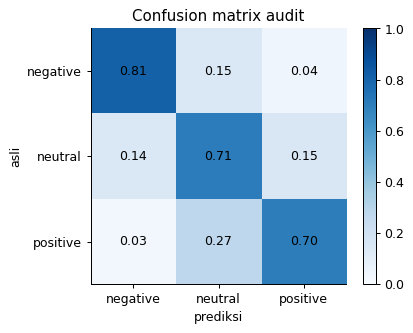

In [18]:
plot_confusion(y_audit, final_pred, CLASSES, "Confusion matrix audit")

**Demo MBG: penandaan aspek.** Zero-shot pada komentar MBG, satu teks bisa punya lebih dari satu aspek.
Komentar ini tidak punya label, jadi yang ditampilkan adalah contoh untuk dinilai sendiri.

In [19]:
HTML_RE = re.compile(r"<[^>]+>")
comments = pd.read_csv(find_file("comment_data.csv"))["Comment"].dropna().astype(str)
comments = comments.sample(n=SETTINGS["aspect_rows"], random_state=SEED)
comments = comments.map(lambda t: clean_text(HTML_RE.sub(" ", html.unescape(t)))).reset_index(
    drop=True
)
aspect_names = list(ASPECTS)
if USE_PRETRAINED:
    with stage("aspek_mbg"):
        aspect_probs = standardize_scores(
            zero_shot(comments.tolist(), [ASPECTS[a] for a in aspect_names])
        )
    aspect_tags = pd.DataFrame(aspect_probs, columns=aspect_names)
    aspect_tags.insert(0, "komentar", comments.str[:90])
    aspect_tags["aspek_utama"] = aspect_tags[aspect_names].idxmax(axis=1)
    aspect_tags.to_csv(RESULT_DIR / "aspek_mbg.csv", index=False)
    print(aspect_tags["aspek_utama"].value_counts(normalize=True).round(3).to_dict())
    display_rows = aspect_tags.sort_values("korupsi", ascending=False)[
        ["komentar", "aspek_utama", "korupsi"]
    ]
else:
    display_rows = pd.DataFrame({"catatan": ["Lewati, zero-shot butuh model pretrained."]})
display_rows.head(5).round(3)

[waktu] aspek_mbg: 53 detik
{'korupsi': 0.268, 'anggaran': 0.241, 'keracunan': 0.193, 'dapur': 0.149, 'gizi': 0.149}


,komentar,aspek_utama,korupsi
2147,yg di bongkar jgn cuma mbg saja. semua sdh terjadi.krn rakyat demo bukan. bongkar juga...,korupsi,0.965
1632,mbg. kartu2 bansos dan bansos langsung itu adalah pola dan cara para rezim jokowi yg d...,korupsi,0.964
1117,"tengkulak jahat sppg sendiri bos mau cuan banyak, telor 1 butir di bagi 4 😂😂😂😂😂 manfaa...",korupsi,0.960
2579,"sebagus analisis anda, indonesia itu negara koruptor yang akut.. sangat rawan maling.....",korupsi,0.960
536,"percuma bang membahas dengan panjang lebar karena inti masalahnya itu korupsi, jadi ke...",korupsi,0.958


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [20]:
submission = pd.DataFrame(
    {
        "id": data.index,
        "label": [CLASSES[i] for i in final_pred],
        "keyakinan": final_probs.max(1).round(3),
    }
)
submission.to_csv(RESULT_DIR / "submission.csv", index=False)
run_summary(
    "weak_supervision",
    len(data),
    {r["model"]: r["macro_f1_audit"] for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=weak_supervision mode=penuh n_rows=5000 total_detik=231 gpu=True
{
 "kata_kunci": 0.4512,
 "zero_shot_mentah": 0.5769,
 "zero_shot": 0.5584,
 "weak_supervision": 0.6753,
 "rata_rata_final": 0.6782
}


**Poin untuk presentasi**

- Macro-F1 audit naik bertahap: kata kunci 0,4512, zero-shot 0,5584, weak supervision 0,6753, rata-rata akhir 0,6782.
- Standardisasi sedikit menurunkan macro-F1 audit (0,5769 ke 0,5584), tapi distribusi kelasnya jauh lebih masuk akal.
- Baris tidak yakin (11,9%) akurasinya 47,1%, sedangkan baris yakin 77,2%. Baris tidak yakin bisa dikirim ke tinjauan manual.
- Aspek MBG dari zero-shot: korupsi 26,8%, anggaran 24,1%, keracunan 19,3%, dapur 14,9%, gizi 14,9%. Bagian ini tanpa audit.